In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Bibliothèques importées avec succès !")

Bibliothèques importées avec succès !


In [4]:
# Chemins des fichiers d'entraînement
train_news_path = "../data/train/news.tsv"
train_behaviors_path = "../data/train/behaviors.tsv"

# Chargement des fichiers TSV
news = pd.read_csv(
    train_news_path,
    sep="\t",
    header=None
)

behaviors = pd.read_csv(
    train_behaviors_path,
    sep="\t",
    header=None
)

print("Dataset chargé avec succès !")

Dataset chargé avec succès !


In [5]:
# Noms des colonnes du fichier news.tsv
news.columns = [
    "news_id",
    "category",
    "subcategory",
    "title",
    "abstract",
    "url",
    "title_entities",
    "abstract_entities"
]

# Noms des colonnes du fichier behaviors.tsv
behaviors.columns = [
    "impression_id",
    "user_id",
    "time",
    "history",
    "impressions"
]

print("Noms des colonnes ajoutés avec succès !")

Noms des colonnes ajoutés avec succès !


In [6]:
print("===== NEWS =====")
display(news.head())

print("===== BEHAVIORS =====")
display(behaviors.head())

===== NEWS =====


,news_id,category,subcategory,title,abstract,url,title_entities,abstract_entities
0,N55528,lifestyle,lifestyleroyals,"The Brands Queen Elizabeth, Prince Charles, an...","Shop the notebooks, jackets, and more that the...",https://assets.msn.com/labs/mind/AAGH0ET.html,"[{""Label"": ""Prince Philip, Duke of Edinburgh"",...",[]
1,N19639,health,weightloss,50 Worst Habits For Belly Fat,These seemingly harmless habits are holding yo...,https://assets.msn.com/labs/mind/AAB19MK.html,"[{""Label"": ""Adipose tissue"", ""Type"": ""C"", ""Wik...","[{""Label"": ""Adipose tissue"", ""Type"": ""C"", ""Wik..."
2,N61837,news,newsworld,The Cost of Trump's Aid Freeze in the Trenches...,Lt. Ivan Molchanets peeked over a parapet of s...,https://assets.msn.com/labs/mind/AAJgNsz.html,[],"[{""Label"": ""Ukraine"", ""Type"": ""G"", ""WikidataId..."
3,N53526,health,voices,I Was An NBA Wife. Here's How It Affected My M...,"I felt like I was a fraud, and being an NBA wi...",https://assets.msn.com/labs/mind/AACk2N6.html,[],"[{""Label"": ""National Basketball Association"", ..."
4,N38324,health,medical,"How to Get Rid of Skin Tags, According to a De...","They seem harmless, but there's a very good re...",https://assets.msn.com/labs/mind/AAAKEkt.html,"[{""Label"": ""Skin tag"", ""Type"": ""C"", ""WikidataI...","[{""Label"": ""Skin tag"", ""Type"": ""C"", ""WikidataI..."


===== BEHAVIORS =====


,impression_id,user_id,time,history,impressions
0,1,U13740,11/11/2019 9:05:58 AM,N55189 N42782 N34694 N45794 N18445 N63302 N104...,N55689-1 N35729-0
1,2,U91836,11/12/2019 6:11:30 PM,N31739 N6072 N63045 N23979 N35656 N43353 N8129...,N20678-0 N39317-0 N58114-0 N20495-0 N42977-0 N...
2,3,U73700,11/14/2019 7:01:48 AM,N10732 N25792 N7563 N21087 N41087 N5445 N60384...,N50014-0 N23877-0 N35389-0 N49712-0 N16844-0 N...
3,4,U34670,11/11/2019 5:28:05 AM,N45729 N2203 N871 N53880 N41375 N43142 N33013 ...,N35729-0 N33632-0 N49685-1 N27581-0
4,5,U8125,11/12/2019 4:11:21 PM,N10078 N56514 N14904 N33740,N39985-0 N36050-0 N16096-0 N8400-1 N22407-0 N6...


In [5]:
# Sélectionner la première ligne
row = behaviors.iloc[0]

# Récupérer l'utilisateur
print("Utilisateur :", row["user_id"])

# Afficher son historique
print("Historique :", row["history"])

# Afficher les articles présentés
print("Impressions :", row["impressions"])

Utilisateur : U13740
Historique : N55189 N42782 N34694 N45794 N18445 N63302 N10414 N19347 N31801
Impressions : N55689-1 N35729-0


In [6]:
# Récupérer l'historique
history = row["history"]

# Transformer la chaîne de caractères en liste
history_list = history.split() if pd.notna(history) else []

print("Nombre d'articles consultés :", len(history_list))
print("Articles consultés :", history_list)

Nombre d'articles consultés : 9
Articles consultés : ['N55189', 'N42782', 'N34694', 'N45794', 'N18445', 'N63302', 'N10414', 'N19347', 'N31801']


In [7]:
print("===== DIMENSIONS DU DATASET =====")

print("Nombre de lignes dans news :", news.shape[0])
print("Nombre de colonnes dans news :", news.shape[1])

print("--------------------------------")

print("Nombre de lignes dans behaviors :", behaviors.shape[0])
print("Nombre de colonnes dans behaviors :", behaviors.shape[1])

===== DIMENSIONS DU DATASET =====
Nombre de lignes dans news : 51282
Nombre de colonnes dans news : 8
--------------------------------
Nombre de lignes dans behaviors : 156965
Nombre de colonnes dans behaviors : 5


In [8]:
print("===== IDENTIFIANTS UNIQUES =====")

print("Nombre d'articles uniques :", news["news_id"].nunique())

print("Nombre d'utilisateurs uniques :", behaviors["user_id"].nunique())

print("Nombre d'impressions uniques :", behaviors["impression_id"].nunique())

===== IDENTIFIANTS UNIQUES =====
Nombre d'articles uniques : 51282
Nombre d'utilisateurs uniques : 50000
Nombre d'impressions uniques : 156965


In [9]:
print("===== VALEURS MANQUANTES : NEWS =====")
print(news.isnull().sum())

print("\n===== VALEURS MANQUANTES : BEHAVIORS =====")
print(behaviors.isnull().sum())

===== VALEURS MANQUANTES : NEWS =====
news_id                 0
category                0
subcategory             0
title                   0
abstract             2666
url                     0
title_entities          3
abstract_entities       4
dtype: int64

===== VALEURS MANQUANTES : BEHAVIORS =====
impression_id       0
user_id             0
time                0
history          3238
impressions         0
dtype: int64


In [10]:
print("===== DOUBLONS =====")

print("Doublons dans news :", news["news_id"].duplicated().sum())

print("Doublons dans behaviors :", behaviors["impression_id"].duplicated().sum())

===== DOUBLONS =====
Doublons dans news : 0
Doublons dans behaviors : 0


===== NOMBRE D'ARTICLES PAR CATÉGORIE =====
category
news             15774
sports           14510
finance           3107
foodanddrink      2551
lifestyle         2479
travel            2350
video             2068
weather           2048
health            1885
autos             1639
tv                 889
music              769
movies             606
entertainment      587
kids                17
middleeast           2
northamerica         1
Name: count, dtype: int64


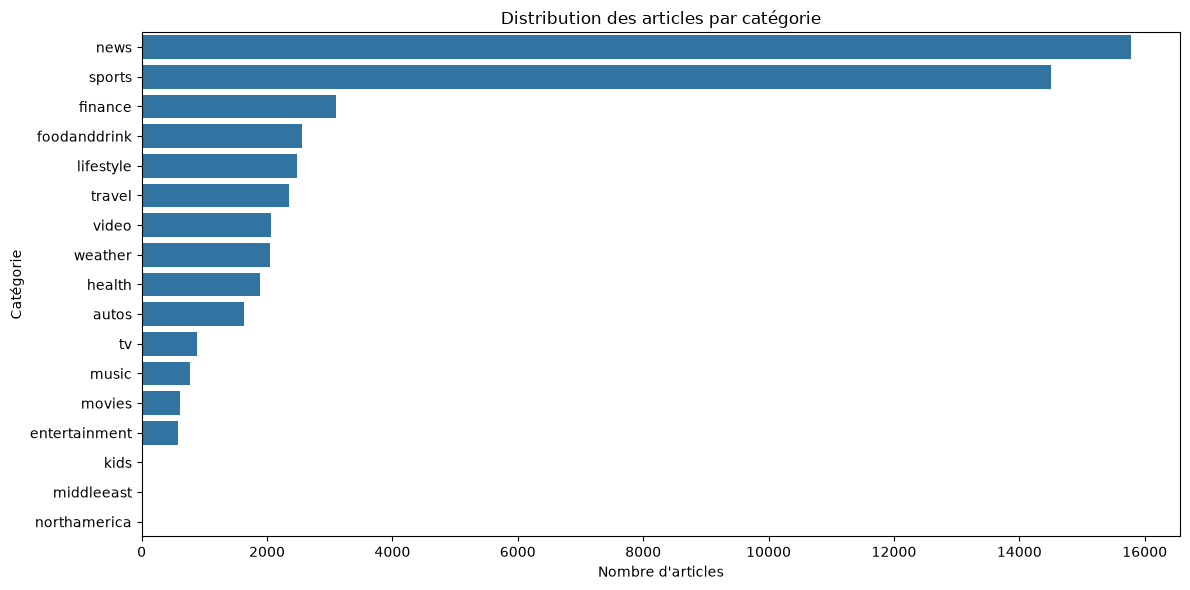

In [11]:
# Nombre d'articles par catégorie
category_counts = news["category"].value_counts()

print("===== NOMBRE D'ARTICLES PAR CATÉGORIE =====")
print(category_counts)

# Visualisation
plt.figure(figsize=(12, 6))

sns.barplot(
    x=category_counts.values,
    y=category_counts.index
)

plt.title("Distribution des articles par catégorie")
plt.xlabel("Nombre d'articles")
plt.ylabel("Catégorie")

plt.tight_layout()
plt.show()

===== TOP 15 SOUS-CATÉGORIES =====
subcategory
newsus                      6564
football_nfl                5420
newspolitics                2826
newscrime                   2254
weathertopstories           2047
newsworld                   1720
football_ncaa               1665
baseball_mlb                1661
basketball_nba              1555
newsscienceandtechnology    1210
news                        1185
newstrends                  1176
more_sports                 1065
travelarticle               1042
travelnews                   902
Name: count, dtype: int64


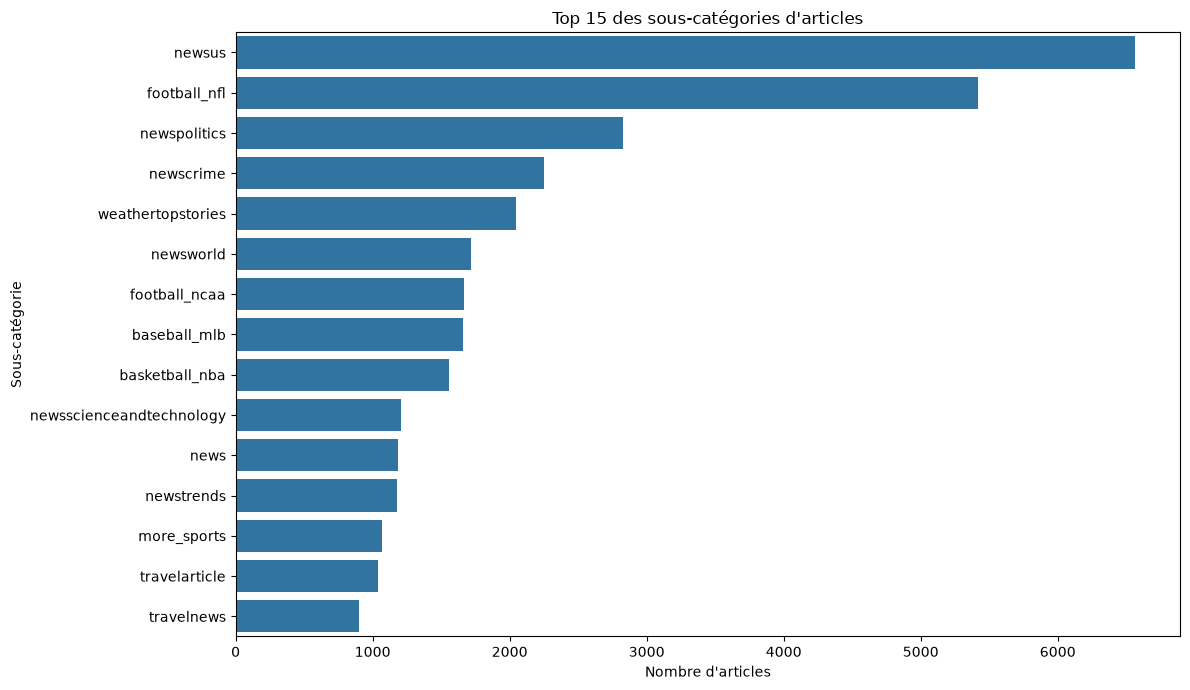

In [12]:
# Les 15 sous-catégories les plus fréquentes
subcategory_counts = news["subcategory"].value_counts().head(15)

print("===== TOP 15 SOUS-CATÉGORIES =====")
print(subcategory_counts)

plt.figure(figsize=(12, 7))

sns.barplot(
    x=subcategory_counts.values,
    y=subcategory_counts.index
)

plt.title("Top 15 des sous-catégories d'articles")
plt.xlabel("Nombre d'articles")
plt.ylabel("Sous-catégorie")

plt.tight_layout()
plt.show()

In [13]:
# Créer une copie des informations nécessaires
impressions_df = behaviors[
    ["impression_id", "user_id", "time", "impressions"]
].copy()

# Séparer les articles présentés
impressions_df["impressions"] = impressions_df["impressions"].str.split()

# Transformer chaque article en une ligne
impressions_df = impressions_df.explode("impressions")

# Séparer l'identifiant de l'article et le label
impressions_df[["news_id", "label"]] = (
    impressions_df["impressions"]
    .str.rsplit("-", n=1, expand=True)
)

# Convertir le label en entier
impressions_df["label"] = impressions_df["label"].astype(int)

# Afficher le résultat
print("===== INTERACTIONS EXTRAITES =====")
display(impressions_df.head(10))

===== INTERACTIONS EXTRAITES =====


,impression_id,user_id,time,impressions,news_id,label
0,1,U13740,11/11/2019 9:05:58 AM,N55689-1,N55689,1
0,1,U13740,11/11/2019 9:05:58 AM,N35729-0,N35729,0
1,2,U91836,11/12/2019 6:11:30 PM,N20678-0,N20678,0
1,2,U91836,11/12/2019 6:11:30 PM,N39317-0,N39317,0
1,2,U91836,11/12/2019 6:11:30 PM,N58114-0,N58114,0
1,2,U91836,11/12/2019 6:11:30 PM,N20495-0,N20495,0
1,2,U91836,11/12/2019 6:11:30 PM,N42977-0,N42977,0
1,2,U91836,11/12/2019 6:11:30 PM,N22407-0,N22407,0
1,2,U91836,11/12/2019 6:11:30 PM,N14592-0,N14592,0
1,2,U91836,11/12/2019 6:11:30 PM,N17059-1,N17059,1


In [14]:
print("===== DISTRIBUTION DES LABELS =====")

print(impressions_df["label"].value_counts())

print("\n===== POURCENTAGES =====")

print(
    impressions_df["label"]
    .value_counts(normalize=True) * 100
)

===== DISTRIBUTION DES LABELS =====
label
0    5607100
1     236344
Name: count, dtype: int64

===== POURCENTAGES =====
label
0    95.955399
1     4.044601
Name: proportion, dtype: float64


In [15]:
# Garder uniquement les articles cliqués
clicks = impressions_df[
    impressions_df["label"] == 1
].copy()

print("===== INTERACTIONS POSITIVES =====")

print("Nombre total de clics :", len(clicks))

display(clicks.head(10))

===== INTERACTIONS POSITIVES =====
Nombre total de clics : 236344


,impression_id,user_id,time,impressions,news_id,label
0,1,U13740,11/11/2019 9:05:58 AM,N55689-1,N55689,1
1,2,U91836,11/12/2019 6:11:30 PM,N17059-1,N17059,1
2,3,U73700,11/14/2019 7:01:48 AM,N23814-1,N23814,1
3,4,U34670,11/11/2019 5:28:05 AM,N49685-1,N49685,1
4,5,U8125,11/12/2019 4:11:21 PM,N8400-1,N8400,1
5,6,U19739,11/11/2019 6:52:13 PM,N21119-1,N21119,1
5,6,U19739,11/11/2019 6:52:13 PM,N33619-1,N33619,1
6,7,U8355,11/11/2019 12:22:09 PM,N55204-1,N55204,1
7,8,U46596,11/12/2019 10:29:36 PM,N33885-1,N33885,1
8,9,U79199,11/13/2019 10:13:02 AM,N51048-1,N51048,1


In [16]:
# Compter le nombre de clics par utilisateur
user_click_counts = clicks.groupby("user_id").size()

print("===== STATISTIQUES DES CLICS PAR UTILISATEUR =====")

print("Nombre d'utilisateurs ayant cliqué :",
      user_click_counts.count())

print("Nombre moyen de clics par utilisateur :",
      user_click_counts.mean())

print("Nombre médian de clics par utilisateur :",
      user_click_counts.median())

print("Nombre minimum de clics :",
      user_click_counts.min())

print("Nombre maximum de clics :",
      user_click_counts.max())

===== STATISTIQUES DES CLICS PAR UTILISATEUR =====
Nombre d'utilisateurs ayant cliqué : 50000
Nombre moyen de clics par utilisateur : 4.72688
Nombre médian de clics par utilisateur : 3.0
Nombre minimum de clics : 1
Nombre maximum de clics : 129


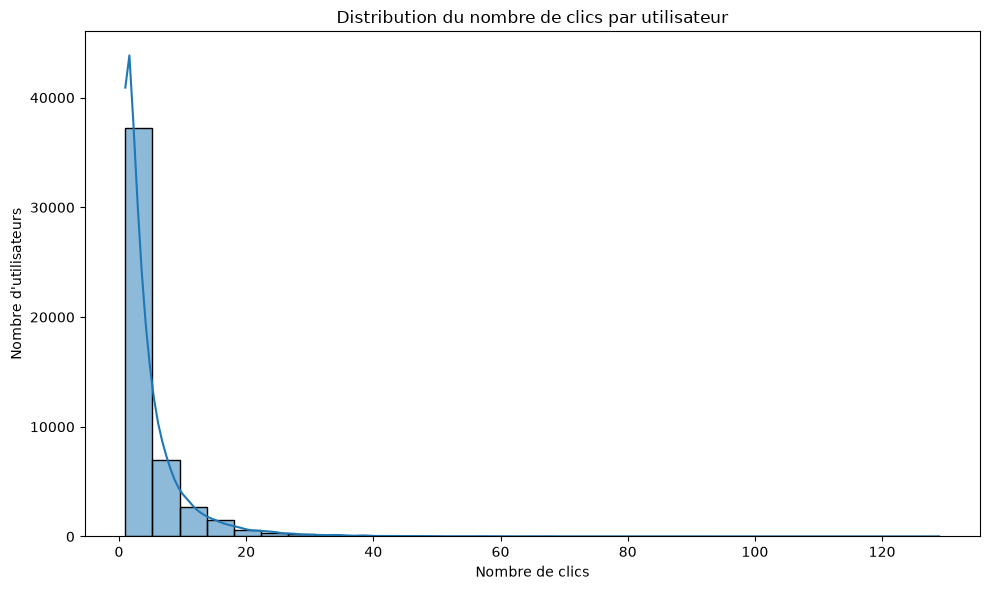

In [17]:
plt.figure(figsize=(10, 6))

sns.histplot(
    user_click_counts,
    bins=30,
    kde=True
)

plt.title("Distribution du nombre de clics par utilisateur")
plt.xlabel("Nombre de clics")
plt.ylabel("Nombre d'utilisateurs")

plt.tight_layout()
plt.show()

In [18]:
# Compter le nombre de clics par article
item_popularity = clicks.groupby("news_id").size()

# Trier les articles par nombre de clics décroissant
item_popularity = item_popularity.sort_values(
    ascending=False
)

print("===== TOP 10 DES ARTICLES LES PLUS CLIQUÉS =====")

print(item_popularity.head(10))

===== TOP 10 DES ARTICLES LES PLUS CLIQUÉS =====
news_id
N55689    4316
N35729    3346
N33619    3246
N53585    2835
N63970    2578
N49685    2294
N49279    2270
N287      2128
N23446    1930
N51048    1875
dtype: int64


In [19]:
# Transformer la popularité en DataFrame
popular_news = item_popularity.reset_index()

popular_news.columns = [
    "news_id",
    "click_count"
]

# Ajouter les informations des articles
popular_news = popular_news.merge(
    news[["news_id", "title", "category", "subcategory"]],
    on="news_id",
    how="left"
)

print("===== TOP 10 DES ARTICLES LES PLUS POPULAIRES =====")

display(popular_news.head(10))

===== TOP 10 DES ARTICLES LES PLUS POPULAIRES =====


,news_id,click_count,title,category,subcategory
0,N55689,4316,"Charles Rogers, former Michigan State football...",sports,football_nfl
1,N35729,3346,Porsche launches into second story of New Jers...,news,newsus
2,N33619,3246,College gymnast dies following training accide...,news,newsus
3,N53585,2835,"Rip Taylor's Cause of Death Revealed, Memorial...",tv,tvnews
4,N63970,2578,Dean Foods files for bankruptcy,finance,finance-companies
5,N49685,2294,Broadway Star Laurel Griggs Suffered Asthma At...,music,music-celebrity
6,N49279,2270,Broadway Actress Laurel Griggs Dies at Age 13,music,musicnews
7,N287,2128,Three school workers charged in death of speci...,news,newscrime
8,N23446,1930,Prince Harry and Meghan Markle just shared a n...,lifestyle,lifestyleroyals
9,N51048,1875,Rep. Tim Ryan endorses Biden in Democratic pri...,news,elections-2020-us


In [20]:
# Vérifier les interactions répétées
duplicate_interactions = clicks.duplicated(
    subset=["user_id", "news_id"]
).sum()

print("===== DOUBLONS D'INTERACTIONS =====")
print("Nombre de couples utilisateur-article répétés :",
      duplicate_interactions)

print("Nombre total de clics :", len(clicks))

print("Nombre de couples utilisateur-article uniques :",
      clicks[["user_id", "news_id"]].drop_duplicates().shape[0])

===== DOUBLONS D'INTERACTIONS =====
Nombre de couples utilisateur-article répétés : 1876
Nombre total de clics : 236344
Nombre de couples utilisateur-article uniques : 234468


In [21]:
# Construire les interactions utilisateur-article uniques
unique_interactions = clicks[
    ["user_id", "news_id"]
].drop_duplicates().copy()

print("===== INTERACTIONS UNIQUES =====")
print("Nombre d'interactions uniques :",
      len(unique_interactions))

display(unique_interactions.head(10))

===== INTERACTIONS UNIQUES =====
Nombre d'interactions uniques : 234468


,user_id,news_id
0,U13740,N55689
1,U91836,N17059
2,U73700,N23814
3,U34670,N49685
4,U8125,N8400
5,U19739,N21119
5,U19739,N33619
6,U8355,N55204
7,U46596,N33885
8,U79199,N51048


In [22]:
# Nombre d'utilisateurs distincts par article
item_unique_popularity = (
    unique_interactions.groupby("news_id")["user_id"]
    .nunique()
    .sort_values(ascending=False)
)

print("===== TOP 10 DES ARTICLES PAR UTILISATEURS DISTINCTS =====")
print(item_unique_popularity.head(10))

===== TOP 10 DES ARTICLES PAR UTILISATEURS DISTINCTS =====
news_id
N55689    4257
N35729    3281
N33619    3214
N53585    2824
N63970    2550
N49685    2273
N49279    2236
N287      2111
N23446    1907
N51048    1861
Name: user_id, dtype: int64


In [23]:
# Nombre d'utilisateurs ayant au moins un clic
n_users = unique_interactions["user_id"].nunique()

# Nombre d'articles ayant au moins un clic
n_items_clicked = unique_interactions["news_id"].nunique()

# Nombre total d'articles dans le catalogue
n_items_total = news["news_id"].nunique()

print("===== DIMENSIONS DE LA MATRICE =====")

print("Nombre d'utilisateurs :", n_users)
print("Articles ayant reçu au moins un clic :", n_items_clicked)
print("Articles dans le catalogue :", n_items_total)

print("Dimensions avec articles cliqués :",
      (n_users, n_items_clicked))

print("Dimensions avec tout le catalogue :",
      (n_users, n_items_total))

===== DIMENSIONS DE LA MATRICE =====
Nombre d'utilisateurs : 50000
Articles ayant reçu au moins un clic : 7713
Articles dans le catalogue : 51282
Dimensions avec articles cliqués : (50000, 7713)
Dimensions avec tout le catalogue : (50000, 51282)


In [24]:
# Nombre de couples utilisateur-article possibles
total_possible_interactions = n_users * n_items_total

# Nombre d'interactions réellement observées
observed_interactions = len(unique_interactions)

# Calcul de la sparsité
sparsity = (
    1 - observed_interactions / total_possible_interactions
) * 100

print("===== SPARSITÉ DE LA MATRICE =====")
print("Interactions possibles :", total_possible_interactions)
print("Interactions observées :", observed_interactions)
print(f"Sparsité : {sparsity:.4f}%")
print(f"Densité : {100 - sparsity:.4f}%")

===== SPARSITÉ DE LA MATRICE =====
Interactions possibles : 2564100000
Interactions observées : 234468
Sparsité : 99.9909%
Densité : 0.0091%


In [25]:
# Nombre d'articles distincts consultés par utilisateur
user_interaction_counts = (
    unique_interactions
    .groupby("user_id")["news_id"]
    .nunique()
)

print("===== INTERACTIONS PAR UTILISATEUR =====")

print("Nombre d'utilisateurs :", len(user_interaction_counts))
print("Moyenne :", user_interaction_counts.mean())
print("Médiane :", user_interaction_counts.median())
print("Minimum :", user_interaction_counts.min())
print("Maximum :", user_interaction_counts.max())

print("\n===== DESCRIPTION STATISTIQUE =====")
display(user_interaction_counts.describe())

===== INTERACTIONS PAR UTILISATEUR =====
Nombre d'utilisateurs : 50000
Moyenne : 4.68936
Médiane : 3.0
Minimum : 1
Maximum : 129

===== DESCRIPTION STATISTIQUE =====


count    50000.000000
mean         4.689360
std          5.701312
min          1.000000
25%          1.000000
50%          3.000000
75%          6.000000
max        129.000000
Name: news_id, dtype: float64

In [26]:
top_users = user_interaction_counts.sort_values(
    ascending=False
).head(10)

print("===== TOP 10 DES UTILISATEURS LES PLUS ACTIFS =====")
display(top_users)

===== TOP 10 DES UTILISATEURS LES PLUS ACTIFS =====


user_id
U53220    129
U70550    119
U63482    112
U32322     96
U20833     92
U79210     88
U40618     84
U72489     82
U79449     80
U59594     78
Name: news_id, dtype: int64

In [27]:
# Nombre d'utilisateurs distincts ayant cliqué sur chaque article
item_interaction_counts = (
    unique_interactions
    .groupby("news_id")["user_id"]
    .nunique()
)

print("===== INTERACTIONS PAR ARTICLE =====")

print("Nombre d'articles :", len(item_interaction_counts))
print("Moyenne :", item_interaction_counts.mean())
print("Médiane :", item_interaction_counts.median())
print("Minimum :", item_interaction_counts.min())
print("Maximum :", item_interaction_counts.max())

print("\n===== DESCRIPTION STATISTIQUE =====")
display(item_interaction_counts.describe())

===== INTERACTIONS PAR ARTICLE =====
Nombre d'articles : 7713
Moyenne : 30.39906651108518
Médiane : 2.0
Minimum : 1
Maximum : 4257

===== DESCRIPTION STATISTIQUE =====


count    7713.000000
mean       30.399067
std       134.799628
min         1.000000
25%         1.000000
50%         2.000000
75%        14.000000
max      4257.000000
Name: user_id, dtype: float64

In [28]:
bottom_items = item_interaction_counts.sort_values(
    ascending=True
).head(10)

print("===== TOP 10 DES ARTICLES LES MOINS POPULAIRES =====")
display(bottom_items)

===== TOP 10 DES ARTICLES LES MOINS POPULAIRES =====


news_id
N10032    1
N9950     1
N9929     1
N9914     1
N39738    1
N39753    1
N39760    1
N39787    1
N10213    1
N10215    1
Name: user_id, dtype: int64

In [29]:
top_items_df = (
    item_interaction_counts
    .sort_values(ascending=False)
    .head(10)
    .reset_index()
)

top_items_df = top_items_df.merge(
    news[["news_id", "title", "category"]],
    on="news_id",
    how="left"
)

top_items_df = top_items_df[
    ["news_id", "title", "category", "user_id"]
]

display(top_items_df)

,news_id,title,category,user_id
0,N55689,"Charles Rogers, former Michigan State football...",sports,4257
1,N35729,Porsche launches into second story of New Jers...,news,3281
2,N33619,College gymnast dies following training accide...,news,3214
3,N53585,"Rip Taylor's Cause of Death Revealed, Memorial...",tv,2824
4,N63970,Dean Foods files for bankruptcy,finance,2550
5,N49685,Broadway Star Laurel Griggs Suffered Asthma At...,music,2273
6,N49279,Broadway Actress Laurel Griggs Dies at Age 13,music,2236
7,N287,Three school workers charged in death of speci...,news,2111
8,N23446,Prince Harry and Meghan Markle just shared a n...,lifestyle,1907
9,N51048,Rep. Tim Ryan endorses Biden in Democratic pri...,news,1861


In [30]:
# Articles sans interaction positive observée
clicked_news_ids = set(unique_interactions["news_id"])
all_news_ids = set(news["news_id"])

news_without_clicks = all_news_ids - clicked_news_ids

print("===== COUVERTURE DU CATALOGUE =====")
print("Nombre total d'articles :", len(all_news_ids))
print("Articles avec clic :", len(clicked_news_ids))
print("Articles sans clic :", len(news_without_clicks))

print(
    "Pourcentage sans clic :",
    round(len(news_without_clicks) / len(all_news_ids) * 100, 2),
    "%"
)

===== COUVERTURE DU CATALOGUE =====
Nombre total d'articles : 51282
Articles avec clic : 7713
Articles sans clic : 43569
Pourcentage sans clic : 84.96 %


In [31]:
# Chemins des fichiers DEV
dev_news_path = "../data/dev/news.tsv"
dev_behaviors_path = "../data/dev/behaviors.tsv"

# Chargement
dev_news = pd.read_csv(
    dev_news_path,
    sep="\t",
    header=None
)

dev_behaviors = pd.read_csv(
    dev_behaviors_path,
    sep="\t",
    header=None
)

# Attribution des noms de colonnes
dev_news.columns = [
    "news_id", "category", "subcategory", "title",
    "abstract", "url", "title_entities", "abstract_entities"
]

dev_behaviors.columns = [
    "impression_id", "user_id", "time",
    "history", "impressions"
]

print("===== DIMENSIONS DEV =====")
print("Articles :", dev_news.shape)
print("Comportements :", dev_behaviors.shape)

display(dev_news.head())
display(dev_behaviors.head())

===== DIMENSIONS DEV =====
Articles : (42416, 8)
Comportements : (73152, 5)


,news_id,category,subcategory,title,abstract,url,title_entities,abstract_entities
0,N55528,lifestyle,lifestyleroyals,"The Brands Queen Elizabeth, Prince Charles, an...","Shop the notebooks, jackets, and more that the...",https://assets.msn.com/labs/mind/AAGH0ET.html,"[{""Label"": ""Prince Philip, Duke of Edinburgh"",...",[]
1,N18955,health,medical,Dispose of unwanted prescription drugs during ...,NaN,https://assets.msn.com/labs/mind/AAISxPN.html,"[{""Label"": ""Drug Enforcement Administration"", ...",[]
2,N61837,news,newsworld,The Cost of Trump's Aid Freeze in the Trenches...,Lt. Ivan Molchanets peeked over a parapet of s...,https://assets.msn.com/labs/mind/AAJgNsz.html,[],"[{""Label"": ""Ukraine"", ""Type"": ""G"", ""WikidataId..."
3,N53526,health,voices,I Was An NBA Wife. Here's How It Affected My M...,"I felt like I was a fraud, and being an NBA wi...",https://assets.msn.com/labs/mind/AACk2N6.html,[],"[{""Label"": ""National Basketball Association"", ..."
4,N38324,health,medical,"How to Get Rid of Skin Tags, According to a De...","They seem harmless, but there's a very good re...",https://assets.msn.com/labs/mind/AAAKEkt.html,"[{""Label"": ""Skin tag"", ""Type"": ""C"", ""WikidataI...","[{""Label"": ""Skin tag"", ""Type"": ""C"", ""WikidataI..."


,impression_id,user_id,time,history,impressions
0,1,U80234,11/15/2019 12:37:50 PM,N55189 N46039 N51741 N53234 N11276 N264 N40716...,N28682-0 N48740-0 N31958-1 N34130-0 N6916-0 N5...
1,2,U60458,11/15/2019 7:11:50 AM,N58715 N32109 N51180 N33438 N54827 N28488 N611...,N20036-0 N23513-1 N32536-0 N46976-0 N35216-0 N...
2,3,U44190,11/15/2019 9:55:12 AM,N56253 N1150 N55189 N16233 N61704 N51706 N5303...,N36779-0 N62365-0 N58098-0 N5472-0 N13408-0 N5...
3,4,U87380,11/15/2019 3:12:46 PM,N63554 N49153 N28678 N23232 N43369 N58518 N444...,N6950-0 N60215-0 N6074-0 N11930-0 N6916-0 N248...
4,5,U9444,11/15/2019 8:25:46 AM,N51692 N18285 N26015 N22679 N55556,N5940-1 N23513-0 N49285-0 N23355-0 N19990-0 N3...


In [32]:
print("===== COMPARAISON TRAIN / DEV =====")

print("Train - Articles :", len(news))
print("Dev - Articles :", len(dev_news))

print("Train - Comportements :", len(behaviors))
print("Dev - Comportements :", len(dev_behaviors))

print(
    "Utilisateurs communs :",
    len(
        set(behaviors["user_id"])
        & set(dev_behaviors["user_id"])
    )
)

print(
    "Articles communs :",
    len(
        set(news["news_id"])
        & set(dev_news["news_id"])
    )
)

===== COMPARAISON TRAIN / DEV =====
Train - Articles : 51282
Dev - Articles : 42416
Train - Comportements : 156965
Dev - Comportements : 73152
Utilisateurs communs : 5943
Articles communs : 28460


In [33]:
# Copie des données pour préserver les données originales
news_clean = news.copy()
dev_news_clean = dev_news.copy()

# Champs textuels à nettoyer
text_columns = [
    "title",
    "abstract",
    "category",
    "subcategory"
]

# Remplacer les valeurs manquantes par des chaînes vides
for col in text_columns:
    news_clean[col] = news_clean[col].fillna("").astype(str)
    dev_news_clean[col] = dev_news_clean[col].fillna("").astype(str)

# Construire le contenu textuel de chaque article
news_clean["content"] = (
    news_clean["title"] + " " +
    news_clean["abstract"] + " " +
    news_clean["category"] + " " +
    news_clean["subcategory"]
)

dev_news_clean["content"] = (
    dev_news_clean["title"] + " " +
    dev_news_clean["abstract"] + " " +
    dev_news_clean["category"] + " " +
    dev_news_clean["subcategory"]
)

print("===== NETTOYAGE DES ARTICLES =====")

print("Valeurs manquantes dans le contenu train :",
      news_clean["content"].isna().sum())

print("Valeurs manquantes dans le contenu dev :",
      dev_news_clean["content"].isna().sum())

display(
    news_clean[
        ["news_id", "title", "category", "subcategory", "content"]
    ].head()
)

===== NETTOYAGE DES ARTICLES =====
Valeurs manquantes dans le contenu train : 0
Valeurs manquantes dans le contenu dev : 0


,news_id,title,category,subcategory,content
0,N55528,"The Brands Queen Elizabeth, Prince Charles, an...",lifestyle,lifestyleroyals,"The Brands Queen Elizabeth, Prince Charles, an..."
1,N19639,50 Worst Habits For Belly Fat,health,weightloss,50 Worst Habits For Belly Fat These seemingly ...
2,N61837,The Cost of Trump's Aid Freeze in the Trenches...,news,newsworld,The Cost of Trump's Aid Freeze in the Trenches...
3,N53526,I Was An NBA Wife. Here's How It Affected My M...,health,voices,I Was An NBA Wife. Here's How It Affected My M...
4,N38324,"How to Get Rid of Skin Tags, According to a De...",health,medical,"How to Get Rid of Skin Tags, According to a De..."


In [34]:
def extract_impressions(behaviors_df):

    # Garder les informations nécessaires
    df = behaviors_df[
        ["impression_id", "user_id", "time", "impressions"]
    ].copy()

    # Séparer les articles affichés
    df["impressions"] = df["impressions"].str.split()

    # Une ligne par article affiché
    df = df.explode("impressions")

    # Séparer news_id et label
    df[["news_id", "label"]] = (
        df["impressions"]
        .str.rsplit("-", n=1, expand=True)
    )

    # Convertir le label en entier
    df["label"] = df["label"].astype(int)

    return df.reset_index(drop=True)

In [35]:
train_impressions = extract_impressions(behaviors)

dev_impressions = extract_impressions(dev_behaviors)

print("===== IMPRESSIONS TRAIN / DEV =====")

print("Train :", train_impressions.shape)
print("Dev :", dev_impressions.shape)

print("\nDistribution des labels TRAIN :")
print(train_impressions["label"].value_counts())

print("\nDistribution des labels DEV :")
print(dev_impressions["label"].value_counts())

===== IMPRESSIONS TRAIN / DEV =====
Train : (5843444, 6)
Dev : (2740998, 6)

Distribution des labels TRAIN :
label
0    5607100
1     236344
Name: count, dtype: int64

Distribution des labels DEV :
label
0    2629615
1     111383
Name: count, dtype: int64


In [36]:
train_clicks = train_impressions[
    train_impressions["label"] == 1
].copy()

train_unique_interactions = (
    train_clicks[["user_id", "news_id"]]
    .drop_duplicates()
    .reset_index(drop=True)
)

print("Interactions positives train :", len(train_clicks))
print("Interactions uniques train :", len(train_unique_interactions))

Interactions positives train : 236344
Interactions uniques train : 234468


In [37]:
def prepare_history(behaviors_df):

    history_df = behaviors_df[
        ["impression_id", "user_id", "history"]
    ].copy()

    # Remplacer les historiques manquants
    history_df["history"] = history_df["history"].fillna("")

    # Transformer chaque historique en liste d'articles
    history_df["history_list"] = (
        history_df["history"]
        .apply(lambda x: x.split())
    )

    # Nombre d'articles dans chaque historique
    history_df["history_length"] = (
        history_df["history_list"].apply(len)
    )

    return history_df

In [38]:
train_history = prepare_history(behaviors)
dev_history = prepare_history(dev_behaviors)

print("===== ANALYSE DE HISTORY =====")

print("Historiques train :", len(train_history))
print("Historiques vides train :",
      (train_history["history_length"] == 0).sum())

print("Moyenne des articles dans history train :",
      train_history["history_length"].mean())

print("\nExemple d'historique :")

display(
    train_history[
        ["user_id", "history_list", "history_length"]
    ].head()
)

===== ANALYSE DE HISTORY =====
Historiques train : 156965
Historiques vides train : 3238
Moyenne des articles dans history train : 32.53998662122129

Exemple d'historique :


,user_id,history_list,history_length
0,U13740,"[N55189, N42782, N34694, N45794, N18445, N6330...",9
1,U91836,"[N31739, N6072, N63045, N23979, N35656, N43353...",82
2,U73700,"[N10732, N25792, N7563, N21087, N41087, N5445,...",16
3,U34670,"[N45729, N2203, N871, N53880, N41375, N43142, ...",10
4,U8125,"[N10078, N56514, N14904, N33740]",4


In [39]:
# Tous les articles connus dans le catalogue train
all_news_ids = set(news["news_id"])

# Extraire tous les articles présents dans les historiques train
history_news_ids = set(
    news_id
    for history in train_history["history_list"]
    for news_id in history
)

# Vérifier les identifiants
known_history_ids = history_news_ids.intersection(all_news_ids)
unknown_history_ids = history_news_ids - all_news_ids

print("===== VALIDATION DES HISTORIQUES =====")
print("Articles distincts dans history :", len(history_news_ids))
print("Articles présents dans news :", len(known_history_ids))
print("Articles absents de news :", len(unknown_history_ids))

print(
    "Pourcentage d'identifiants connus :",
    round(len(known_history_ids) / len(history_news_ids) * 100, 2),
    "%"
)

===== VALIDATION DES HISTORIQUES =====
Articles distincts dans history : 33195
Articles présents dans news : 33195
Articles absents de news : 0
Pourcentage d'identifiants connus : 100.0 %


In [40]:
# Copier les données originales
news_clean = news.copy()
dev_news_clean = dev_news.copy()

text_columns = [
    "title",
    "abstract",
    "category",
    "subcategory"
]

# Remplacer les valeurs manquantes
for col in text_columns:
    news_clean[col] = news_clean[col].fillna("").astype(str)
    dev_news_clean[col] = dev_news_clean[col].fillna("").astype(str)

# Construire le texte de chaque article
for df in [news_clean, dev_news_clean]:

    df["content"] = (
        df["title"] + " " +
        df["abstract"] + " " +
        df["category"] + " " +
        df["subcategory"]
    )

print("===== CONTENU DES ARTICLES =====")
display(
    news_clean[
        ["news_id", "title", "category", "content"]
    ].head()
)

===== CONTENU DES ARTICLES =====


,news_id,title,category,content
0,N55528,"The Brands Queen Elizabeth, Prince Charles, an...",lifestyle,"The Brands Queen Elizabeth, Prince Charles, an..."
1,N19639,50 Worst Habits For Belly Fat,health,50 Worst Habits For Belly Fat These seemingly ...
2,N61837,The Cost of Trump's Aid Freeze in the Trenches...,news,The Cost of Trump's Aid Freeze in the Trenches...
3,N53526,I Was An NBA Wife. Here's How It Affected My M...,health,I Was An NBA Wife. Here's How It Affected My M...
4,N38324,"How to Get Rid of Skin Tags, According to a De...",health,"How to Get Rid of Skin Tags, According to a De..."


In [41]:
# Construire un catalogue global sans dupliquer les news_id
news_catalog = pd.concat(
    [news_clean, dev_news_clean],
    ignore_index=True
).drop_duplicates(subset="news_id", keep="first")

# Vérifier les interactions train
train_item_ids = set(train_unique_interactions["news_id"])
catalog_item_ids = set(news_catalog["news_id"])

missing_train_items = train_item_ids - catalog_item_ids

# Vérifier les articles affichés dans dev
dev_item_ids = set(dev_impressions["news_id"])
missing_dev_items = dev_item_ids - catalog_item_ids

print("===== COUVERTURE DU CATALOGUE GLOBAL =====")
print("Articles uniques dans le catalogue :", len(news_catalog))
print("Articles train absents du catalogue :", len(missing_train_items))
print("Articles dev absents du catalogue :", len(missing_dev_items))

===== COUVERTURE DU CATALOGUE GLOBAL =====
Articles uniques dans le catalogue : 65238
Articles train absents du catalogue : 0
Articles dev absents du catalogue : 0


In [43]:
from scipy.sparse import csr_matrix

# Créer les correspondances entre identifiants et indices
user_ids = sorted(train_unique_interactions["user_id"].unique())
item_ids = sorted(news_catalog["news_id"].unique())

user_to_idx = {
    user_id: idx for idx, user_id in enumerate(user_ids)
}

item_to_idx = {
    item_id: idx for idx, item_id in enumerate(item_ids)
}

# Transformer les identifiants en indices
user_indices = train_unique_interactions["user_id"].map(user_to_idx)
item_indices = train_unique_interactions["news_id"].map(item_to_idx)

# Construire la matrice creuse utilisateur-article
interaction_matrix = csr_matrix(
    (
        np.ones(len(train_unique_interactions), dtype=np.float32),
        (user_indices, item_indices)
    ),
    shape=(len(user_ids), len(item_ids))
)

print("===== MATRICE UTILISATEUR-ARTICLE =====")
print("Dimensions :", interaction_matrix.shape)
print("Nombre d'interactions :", interaction_matrix.nnz)
print("Type :", type(interaction_matrix))
print("Taille mémoire (Mo) :",
      round(
          (interaction_matrix.data.nbytes +
           interaction_matrix.indices.nbytes +
           interaction_matrix.indptr.nbytes) / (1024 ** 2),
          2
      ))

===== MATRICE UTILISATEUR-ARTICLE =====
Dimensions : (50000, 65238)
Nombre d'interactions : 234468
Type : <class 'scipy.sparse._csr.csr_matrix'>
Taille mémoire (Mo) : 1.98


In [44]:
from sklearn.feature_extraction.text import TfidfVectorizer

# Créer le vectoriseur TF-IDF
tfidf_vectorizer = TfidfVectorizer(
    lowercase=True,
    stop_words="english",
    max_features=20000,
    ngram_range=(1, 2),
    min_df=2
)

# Apprendre le vocabulaire sur le catalogue disponible
tfidf_matrix = tfidf_vectorizer.fit_transform(
    news_catalog["content"]
)

print("===== REPRESENTATION TF-IDF =====")
print("Dimensions :", tfidf_matrix.shape)
print("Nombre de termes :", len(tfidf_vectorizer.vocabulary_))
print("Type :", type(tfidf_matrix))
print("Taille mémoire (Mo) :",
      round(
          (tfidf_matrix.data.nbytes +
           tfidf_matrix.indices.nbytes +
           tfidf_matrix.indptr.nbytes) / (1024 ** 2),
          2
      ))

===== REPRESENTATION TF-IDF =====
Dimensions : (65238, 20000)
Nombre de termes : 20000
Type : <class 'scipy.sparse._csr.csr_matrix'>
Taille mémoire (Mo) : 20.69


In [45]:
# Associer chaque article à son indice dans la matrice TF-IDF
# Préparer les historiques train et dev

def map_history_to_indices(history_list, item_to_idx):

    return [
        item_to_idx[news_id]
        for news_id in history_list
        if news_id in item_to_idx
    ]


train_history["history_indices"] = train_history["history_list"].apply(
    lambda x: map_history_to_indices(x, item_to_idx)
)

dev_history["history_indices"] = dev_history["history_list"].apply(
    lambda x: map_history_to_indices(x, item_to_idx)
)

print("===== PREPARATION DES PROFILS =====")
print("Historique train moyen :",
      train_history["history_indices"].apply(len).mean())

print("Historique dev moyen :",
      dev_history["history_indices"].apply(len).mean())

display(
    train_history[
        ["user_id", "history_length", "history_indices"]
    ].head()
)

===== PREPARATION DES PROFILS =====
Historique train moyen : 32.53998662122129
Historique dev moyen : 32.29595909886264


,user_id,history_length,history_indices
0,U13740,9,"[50211, 36426, 27439, 39772, 9385, 59227, 463,..."
1,U91836,82,"[24156, 56357, 58941, 15533, 28508, 37061, 631..."
2,U73700,16,"[816, 17548, 62532, 12321, 34543, 49390, 55984..."
3,U34670,10,"[39700, 13369, 63806, 48757, 34863, 36827, 255..."
4,U8125,4,"[89, 51684, 5451, 26380]"


In [46]:
# Conserver l'ordre du catalogue utilisé pour construire TF-IDF
news_catalog = (
    news_catalog
    .drop_duplicates(subset="news_id", keep="first")
    .reset_index(drop=True)
)

# Chaque ligne TF-IDF correspondra au même indice dans item_to_idx
item_ids = news_catalog["news_id"].tolist()

item_to_idx = {
    news_id: idx
    for idx, news_id in enumerate(item_ids)
}

# Mapping des utilisateurs
user_ids = sorted(train_unique_interactions["user_id"].unique())

user_to_idx = {
    user_id: idx
    for idx, user_id in enumerate(user_ids)
}

# Reconstruire la matrice utilisateur-article
user_indices = train_unique_interactions["user_id"].map(user_to_idx)
item_indices = train_unique_interactions["news_id"].map(item_to_idx)

interaction_matrix = csr_matrix(
    (
        np.ones(len(train_unique_interactions), dtype=np.float32),
        (user_indices, item_indices)
    ),
    shape=(len(user_ids), len(item_ids))
)

# Vérifier les dimensions et l'alignement
print("===== VERIFICATION DE L'ALIGNEMENT =====")
print("Catalogue :", len(news_catalog))
print("Matrice CF :", interaction_matrix.shape)
print("Matrice TF-IDF :", tfidf_matrix.shape)
print("Premier article du catalogue :", news_catalog.iloc[0]["news_id"])
print("Article associé à l'indice 0 :", item_ids[0])

assert interaction_matrix.shape[1] == tfidf_matrix.shape[0]
assert item_ids[0] == news_catalog.iloc[0]["news_id"]

print("\nAlignement vérifié !")

===== VERIFICATION DE L'ALIGNEMENT =====
Catalogue : 65238
Matrice CF : (50000, 65238)
Matrice TF-IDF : (65238, 20000)
Premier article du catalogue : N55528
Article associé à l'indice 0 : N55528

Alignement vérifié !


In [47]:
def map_history_to_indices(history_list, item_to_idx):
    return [
        item_to_idx[news_id]
        for news_id in history_list
        if news_id in item_to_idx
    ]

train_history["history_indices"] = train_history["history_list"].apply(
    lambda x: map_history_to_indices(x, item_to_idx)
)

dev_history["history_indices"] = dev_history["history_list"].apply(
    lambda x: map_history_to_indices(x, item_to_idx)
)

print("Historiques train préparés :", len(train_history))
print("Historiques dev préparés :", len(dev_history))
print("\nExemple :")
print(train_history[["user_id", "history_length", "history_indices"]].head())

Historiques train préparés : 156965
Historiques dev préparés : 73152

Exemple :
  user_id  history_length                                    history_indices
0  U13740               9  [6892, 10049, 15555, 21466, 26357, 4945, 14070...
1  U91836              82  [25815, 2333, 8523, 12086, 13462, 14201, 12732...
2  U73700              16  [5476, 4206, 11683, 7703, 8123, 23393, 22969, ...
3  U34670              10  [13826, 19084, 28505, 7023, 22909, 16666, 1559...
4   U8125               4                        [23642, 4852, 27685, 31188]


In [48]:
# Utilisateurs connus de la matrice collaborative
train_users = set(train_unique_interactions["user_id"].unique())

# Articles ayant reçu au moins un clic positif dans train
train_clicked_items = set(train_unique_interactions["news_id"].unique())

# Utilisateurs et articles présents dans les impressions dev
dev_users = set(dev_impressions["user_id"].unique())
dev_items = set(dev_impressions["news_id"].unique())

# Nouveaux utilisateurs pour le modèle CF
new_users = dev_users - train_users

# Articles sans interaction positive dans train
new_items = dev_items - train_clicked_items

print("===== ANALYSE DU COLD-START =====")

print("Utilisateurs dev :", len(dev_users))
print("Nouveaux utilisateurs :", len(new_users))
print(
    "Taux nouveaux utilisateurs :",
    round(len(new_users) / len(dev_users) * 100, 2), "%"
)

print("\nArticles présents dans dev :", len(dev_items))
print("Articles sans clic positif dans train :", len(new_items))
print(
    "Taux d'articles sans interaction train :",
    round(len(new_items) / len(dev_items) * 100, 2), "%"
)

===== ANALYSE DU COLD-START =====
Utilisateurs dev : 50000
Nouveaux utilisateurs : 44057
Taux nouveaux utilisateurs : 88.11 %

Articles présents dans dev : 5369
Articles sans clic positif dans train : 3535
Taux d'articles sans interaction train : 65.84 %


In [49]:
print("===== QUALITÉ DES HISTORIQUES DEV =====")

print(
    "Nombre d'historiques vides :",
    (dev_history["history_length"] == 0).sum()
)

print(
    "Nombre d'historiques non vides :",
    (dev_history["history_length"] > 0).sum()
)

print(
    "Longueur moyenne :",
    round(dev_history["history_length"].mean(), 2)
)

print(
    "Longueur médiane :",
    dev_history["history_length"].median()
)

print(
    "Nombre d'historiques sans article reconnu :",
    (dev_history["history_indices"].apply(len) == 0).sum()
)

===== QUALITÉ DES HISTORIQUES DEV =====
Nombre d'historiques vides : 2214
Nombre d'historiques non vides : 70938
Longueur moyenne : 32.3
Longueur médiane : 19.0
Nombre d'historiques sans article reconnu : 2214


In [50]:
import os
import json
from scipy.sparse import save_npz

os.makedirs("../data/processed", exist_ok=True)

# Matrices
save_npz(
    "../data/processed/interaction_matrix.npz",
    interaction_matrix
)

save_npz(
    "../data/processed/tfidf_matrix.npz",
    tfidf_matrix
)

# Catalogue des articles
news_catalog.to_csv(
    "../data/processed/news_catalog.csv",
    index=False
)

# Interactions positives uniques
train_unique_interactions.to_csv(
    "../data/processed/train_interactions.csv",
    index=False
)

# Impressions de validation
dev_impressions.to_csv(
    "../data/processed/dev_impressions.csv.gz",
    index=False,
    compression="gzip"
)

# Historiques préparés
train_history.to_pickle(
    "../data/processed/train_history.pkl"
)

dev_history.to_pickle(
    "../data/processed/dev_history.pkl"
)

# Correspondances entre identifiants et indices
with open("../data/processed/mappings.json", "w") as f:
    json.dump(
        {
            "user_to_idx": user_to_idx,
            "item_to_idx": item_to_idx
        },
        f
    )

print("Toutes les données préparées ont été sauvegardées.")

Toutes les données préparées ont été sauvegardées.


In [51]:
import joblib

joblib.dump(
    tfidf_vectorizer,
    "../data/processed/tfidf_vectorizer.pkl"
)

['../data/processed/tfidf_vectorizer.pkl']